In [1]:
from scipy.io import loadmat
from scipy.stats import pearsonr, ttest_ind
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="white", context="paper", font_scale=1.5, font="Arial")

In [2]:
abcd_err = loadmat("results/ABCD/cbpp/4278sub_34behaviors/avg_PredErr_SVR.mat")["err_avg"]
abcd_conf = pd.read_csv("results/ABCD/lists/ABCD_conf_split.csv")
# ABCD clusters: Verbal memory, Cognition, CBCL, Prodromal Psychosis
print(abcd_err[0][0][0].shape, abcd_err[0][0][1].shape, abcd_err[0][0][2].shape, abcd_err[0][0][3].shape)

hcpd_err = loadmat("results/HCP-D/cbpp/432sub_22behaviors/avg_PredErr_SVR.mat")["err_avg"]
hcpd_conf = pd.read_csv("results/HCP-D/lists/HCP-D_conf_split.csv")
# HCP-D clusters: Cognition, Emotion recognition
print(hcpd_err[0][0][0].shape, hcpd_err[0][0][1].shape)

hcp_err = loadmat("results/HCP/cbpp/784sub_51behaviors/avg_PredErr_SVR.mat")["err_avg"]
hcp_conf = pd.read_csv("results/HCP/lists/HCP_conf_split.csv")
# HCP clusters: Social cognition, Negative / positive feelings, Emotion recognition
print(hcp_err[0][0][0].shape, hcp_err[0][0][1].shape, hcp_err[0][0][2].shape)

(4278, 1) (4278, 1) (4278, 1) (4278, 1)
(432, 1) (432, 1)
(784, 1) (784, 1) (784, 1)


In [3]:
def plot_scatter(x: np.ndarray, y: np.ndarray, cluster: str, covariate: str, ax):
    nas = np.logical_or(np.isnan(x), np.isnan(y))
    sns.regplot(ax=ax, x=np.log(x[~nas]), y=np.log(y[~nas]), marker="x", scatter_kws={"color": ".2"}, line_kws={"color": "red"})
    
    r, p = pearsonr(np.log(x[~nas]), np.log(y[~nas]))
    ax.set_title(f"{cluster}\n R = {np.round(r, 4)}, p = {p: .2E}", fontsize=20)
    
    ax.set_ylabel("Prediction error (log scale)", fontsize=16)
    ax.set_xlabel(f"{covariate} (log scale)", fontsize=16)
    sns.despine(ax=ax)

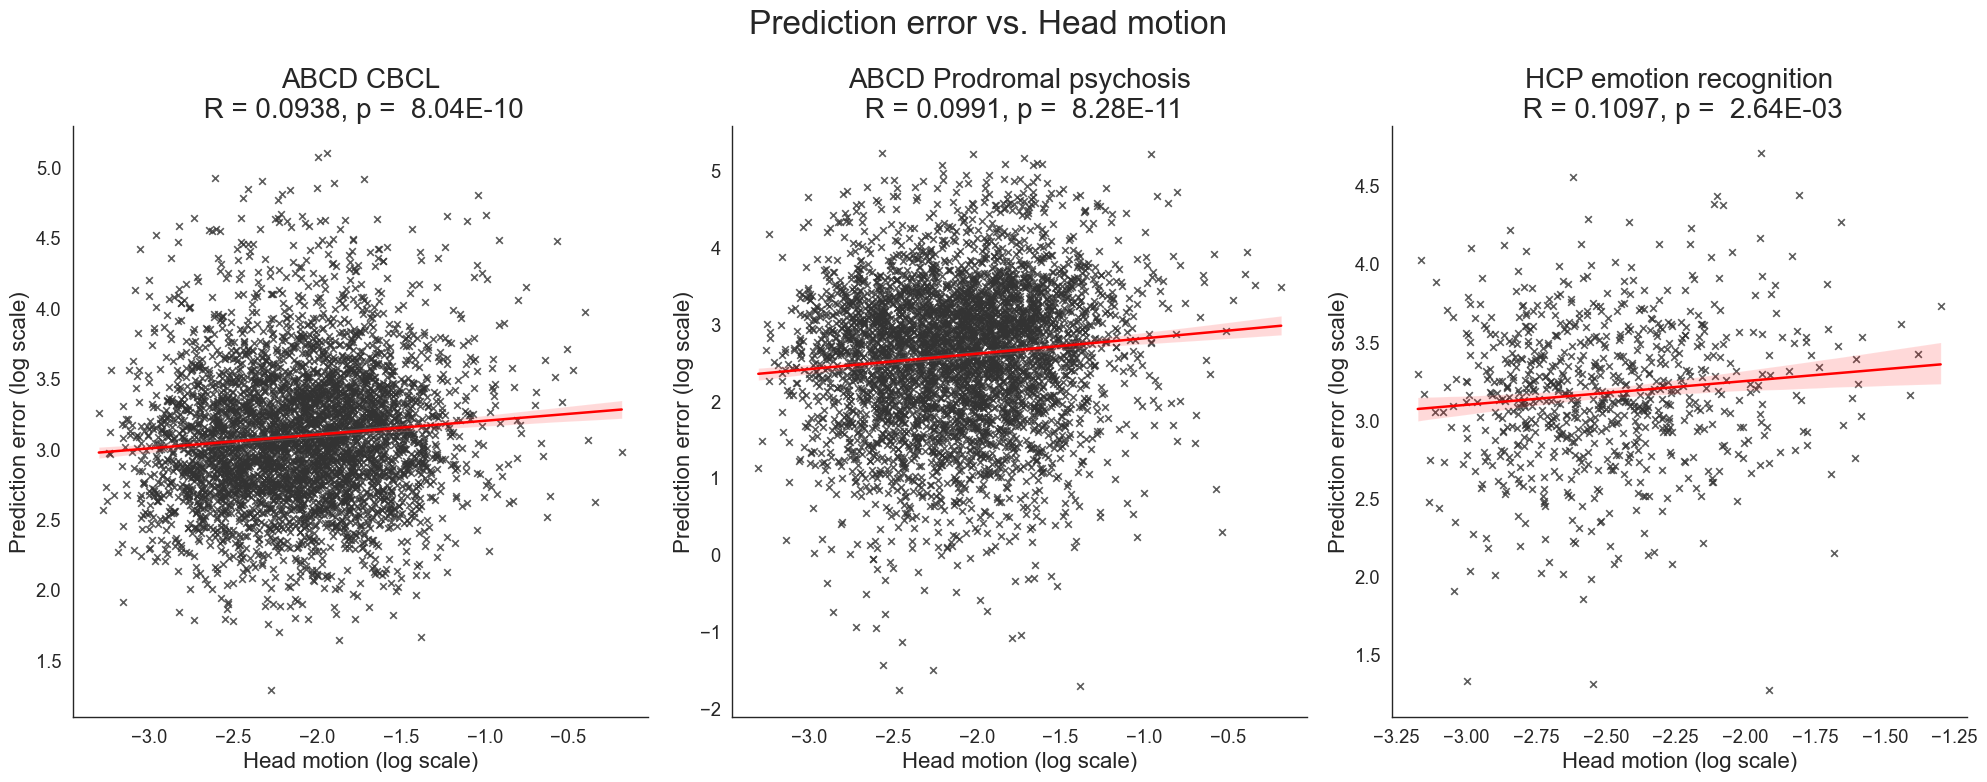

In [4]:
# FD: ABCD CBCL, ABCD Prodromal psychosis, HCP emotion recognition
f, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 8))
plt.suptitle("Prediction error vs. Head motion", fontsize=24)

plot_scatter(abcd_conf["FD"].to_numpy(), abcd_err[0][0][2].squeeze(), "ABCD CBCL", "Head motion", ax[0])
plot_scatter(abcd_conf["FD"].to_numpy(), abcd_err[0][0][3].squeeze(), "ABCD Prodromal psychosis", "Head motion", ax[1])
plot_scatter(hcp_conf["FD"].to_numpy(), hcp_err[0][0][2].squeeze(), "HCP emotion recognition", "Head motion", ax[2])

f.tight_layout()
f.savefig("plots/pred_err_vs_fd.png", dpi=500)

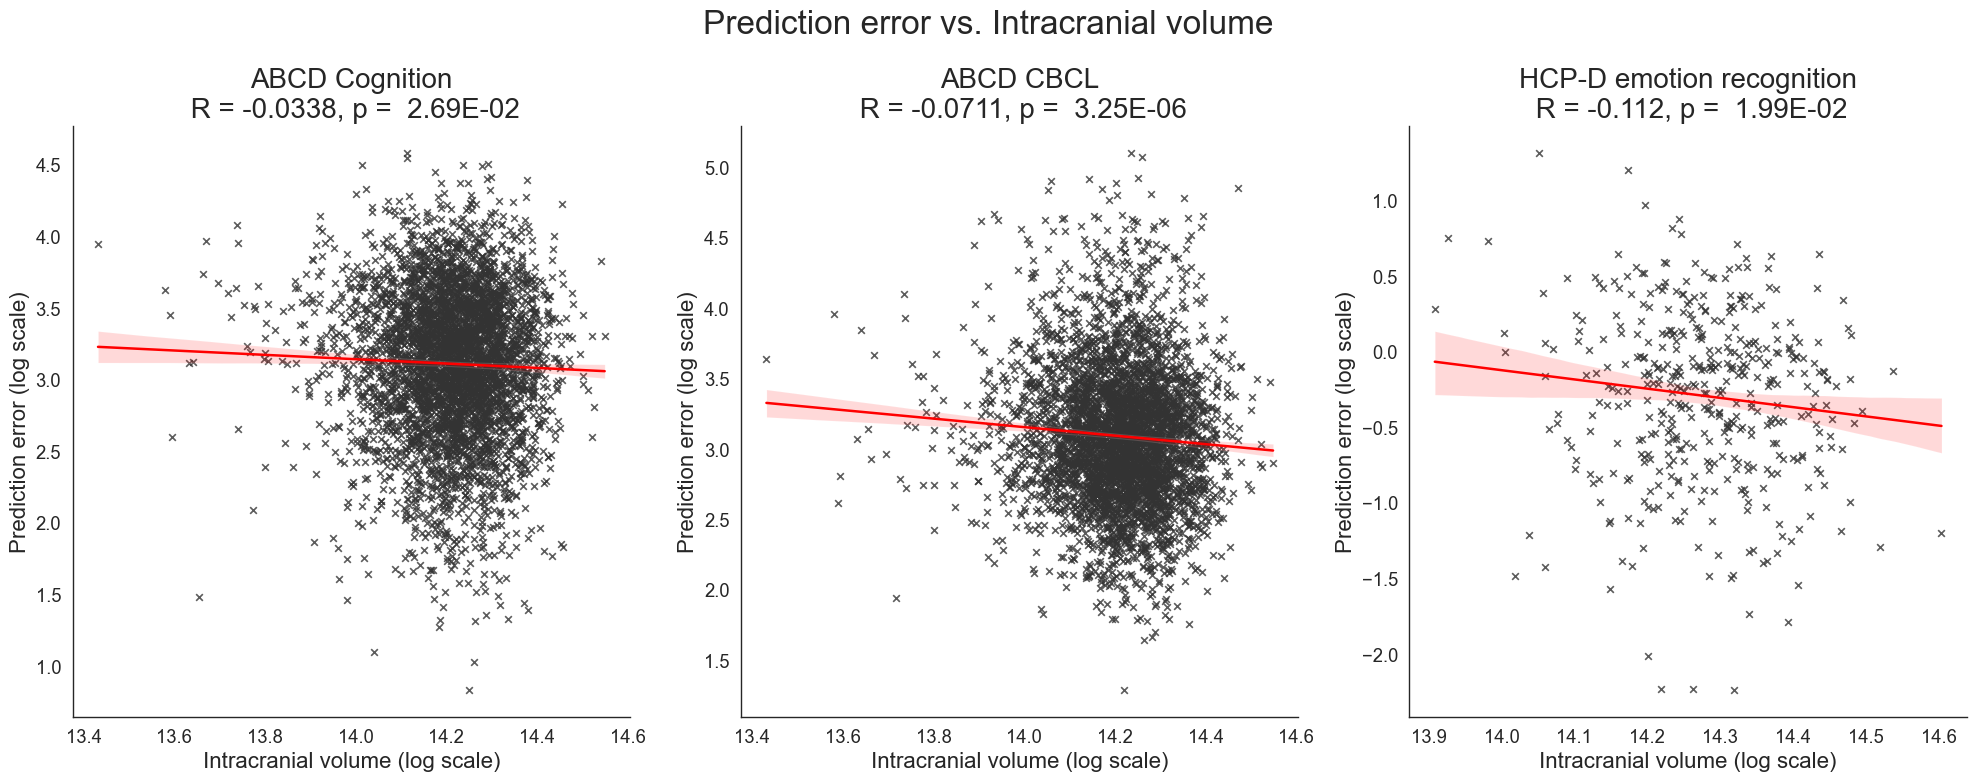

In [5]:
# ICV: ABCD cognition, ABCD CBCL, HCP-D emotion recognition
f, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 8))
plt.suptitle("Prediction error vs. Intracranial volume", fontsize=24)

plot_scatter(abcd_conf["ICV"].to_numpy(), abcd_err[0][0][1].squeeze(), "ABCD Cognition", "Intracranial volume", ax[0])
plot_scatter(abcd_conf["ICV"].to_numpy(), abcd_err[0][0][2].squeeze(), "ABCD CBCL", "Intracranial volume", ax[1])
plot_scatter(hcpd_conf["ICV"].to_numpy(), hcpd_err[0][0][1].squeeze(), "HCP-D emotion recognition", "Intracranial volume", ax[2])

f.tight_layout()
f.savefig("plots/pred_err_vs_icv.png", dpi=500)

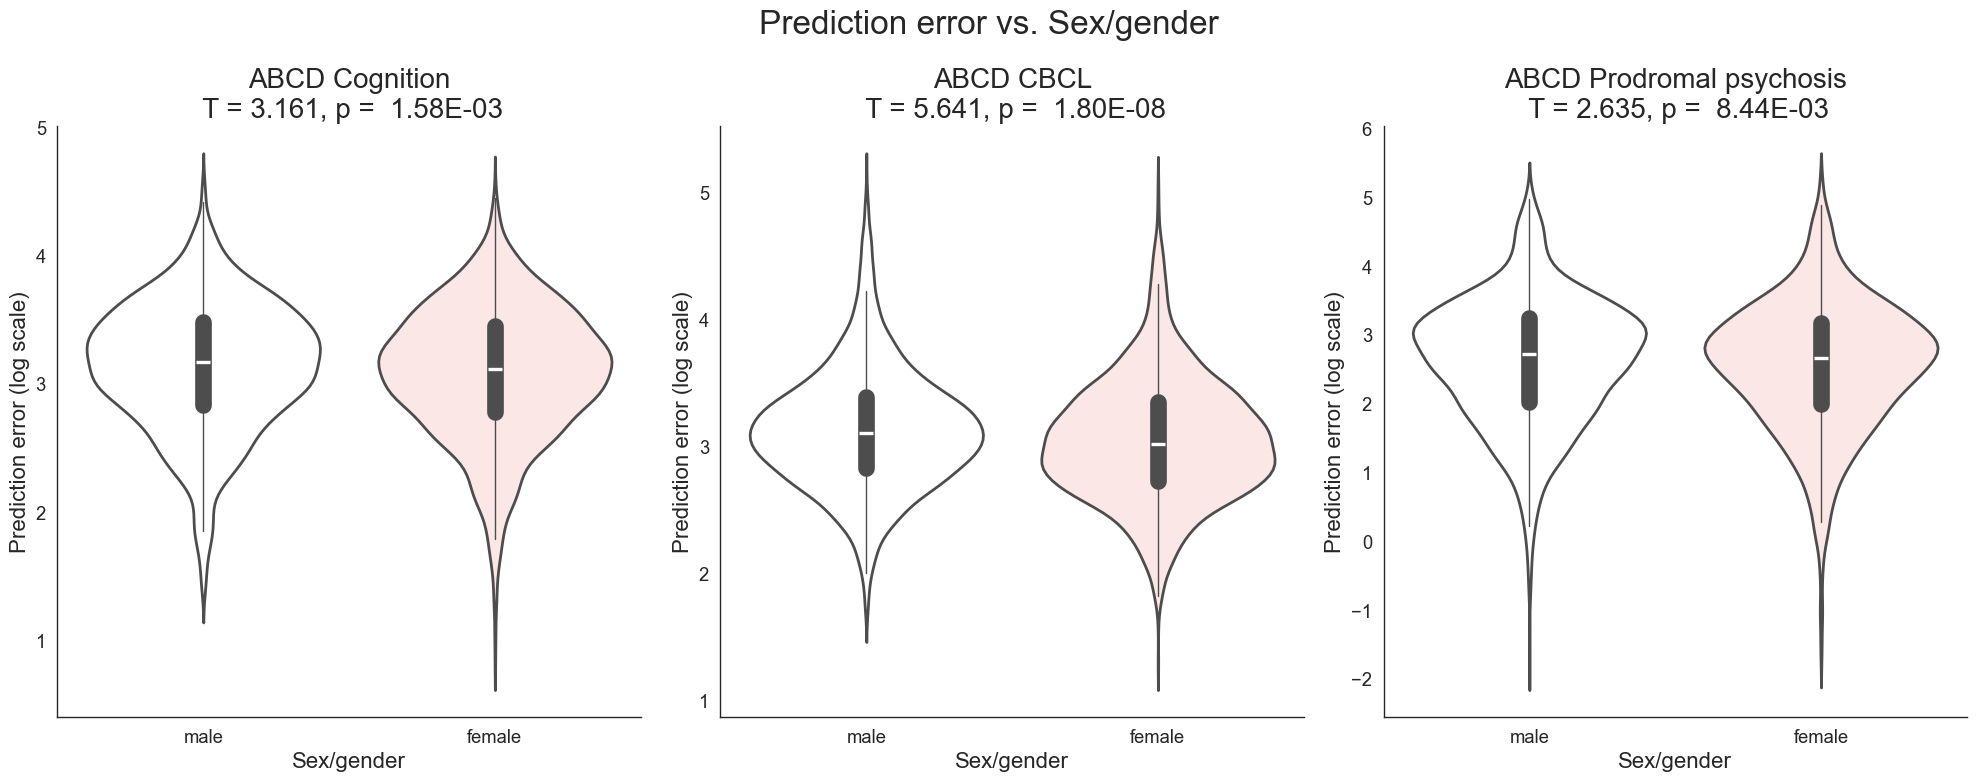

In [6]:
def plot_violin(x: np.ndarray, y: np.ndarray, cluster: str, covariate: str, ax):
    sns.violinplot(
        ax=ax, x=x, y=np.log(y), hue=x, palette={"male": "white", "female": "mistyrose"}, linecolor=".3", linewidth=2,
        inner_kws={"box_width": 12, "whis_width": 1, "color": ".3"})

    res = ttest_ind(
        [err for sex, err in zip(x, np.log(y)) if sex == "male"], [err for sex, err in zip(x, np.log(y)) if sex == "female"],
        equal_var=False)
    ax.set_title(f"{cluster}\n T = {np.round(res.statistic, 3)}, p = {res.pvalue: .2E}", fontsize=20)
    
    ax.set_ylabel("Prediction error (log scale)", fontsize=16)
    ax.set_xlabel(covariate, fontsize=16)
    sns.despine(ax=ax)

# sex/gender: ABCD cognition, ABCD CBCL, ABCD Prodromal psychosis
sex_dict = {0: "male", 1: "female"}
abcd_sex = np.array([sex_dict[sex] for sex in abcd_conf["sex_F"]])
f, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 8))
plt.suptitle("Prediction error vs. Sex/gender", fontsize=24)

plot_violin(abcd_sex, abcd_err[0][0][1].squeeze(), "ABCD Cognition", "Sex/gender", ax[0])
plot_violin(abcd_sex, abcd_err[0][0][2].squeeze(), "ABCD CBCL", "Sex/gender", ax[1])
plot_violin(abcd_sex, abcd_err[0][0][3].squeeze(), "ABCD Prodromal psychosis", "Sex/gender", ax[2])

f.tight_layout()
f.savefig("plots/pred_err_vs_sex.png", dpi=500)